# Company A Telecom — Data Analysis and Churn Prediction

**Run this notebook in VS Code.** It calls reusable functions from the `src/` Python modules.

Assignment context: the supplied dataset overview defines `churn` as churn 31–60 days after the observation date. This notebook investigates that target as an initial hypothesis; interpret all outputs using the assignment documentation and observed results.

## 1. Imports and project setup

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_data, check_target
from src.eda import save_data_profile, plot_target_distribution, plot_missing_values, numeric_summary, plot_numeric_by_target,plot_distributions,plot_correlation_heatmap,plot_churn_by_category,plot_scatter
from src.modeling import train_compare_models, feature_importance
from src.evaluation import evaluate_selected_model
from src.business import make_risk_ranking, top_group_lift, scenario_calculator
from src.narrative import metrics_summary, business_summary

pd.set_option("display.max_columns", 100)
print("Notebook folder:", Path.cwd())

Notebook folder: c:\Users\princ\Company_A_Telecom_Project


## 2. Load and merge the supplied data

In [2]:
client, record, df = load_data()

print("Client shape:", client.shape)
print("Record shape:", record.shape)
print("Merged shape:", df.shape)
display(df.head())

Client shape: (100000, 50)
Record shape: (100000, 51)
Merged shape: (100000, 100)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0


## 3. Validate target and profile the dataset

In [3]:
target_counts, target_shares = check_target(df)
print("Target counts:")
display(target_counts.to_frame("count"))
print("Target proportions:")
display(target_shares.to_frame("proportion"))

profile = save_data_profile(df)
display(profile.head(25))
display(numeric_summary(df).head(25))

Target counts:


,count
churn,
0,50438
1,49562


Target proportions:


,proportion
churn,
0,0.5044
1,0.4956


,dtype,missing_count,missing_percent,unique_values
numbcars,float64,49366,49.37,3
dwllsize,str,38308,38.31,15
HHstatin,str,37923,37.92,6
ownrent,str,33706,33.71,2
dwlltype,str,31909,31.91,2
lor,float64,30190,30.19,16
income,float64,25436,25.44,9
adults,float64,23019,23.02,6
infobase,str,22079,22.08,2
hnd_webcap,str,10189,10.19,3


,count,mean,std,min,25%,50%,75%,max
rev_Mean,99643.0,58.719985,46.291677,-6.1675,33.260000,48.195000,70.750000,3843.262500
mou_Mean,99643.0,513.559937,525.168140,0.0000,150.750000,355.500000,703.000000,12206.750000
totmrc_Mean,99643.0,46.179136,23.623489,-26.9150,30.000000,44.990000,59.990000,409.990000
da_Mean,99643.0,0.888828,2.177619,0.0000,0.000000,0.247500,0.990000,159.390000
ovrmou_Mean,99643.0,41.072247,97.296150,0.0000,0.000000,2.750000,42.000000,4320.750000
ovrrev_Mean,99643.0,13.559560,30.500885,0.0000,0.000000,1.000000,14.437500,1102.400000
vceovr_Mean,99643.0,13.295062,30.056089,0.0000,0.000000,0.682500,14.025000,896.087500
datovr_Mean,99643.0,0.261318,3.126531,0.0000,0.000000,0.000000,0.000000,423.540000
roam_Mean,99643.0,1.286405,14.711374,0.0000,0.000000,0.000000,0.235000,3685.200000
change_mou,99109.0,-13.933818,276.087509,-3875.0000,-87.000000,-6.250000,63.000000,31219.250000


## 4. Exploratory data analysis

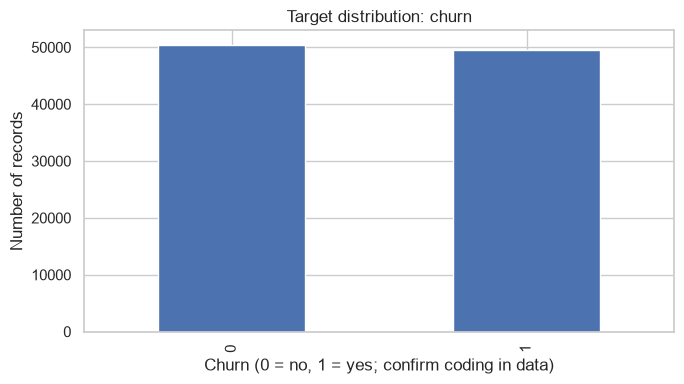

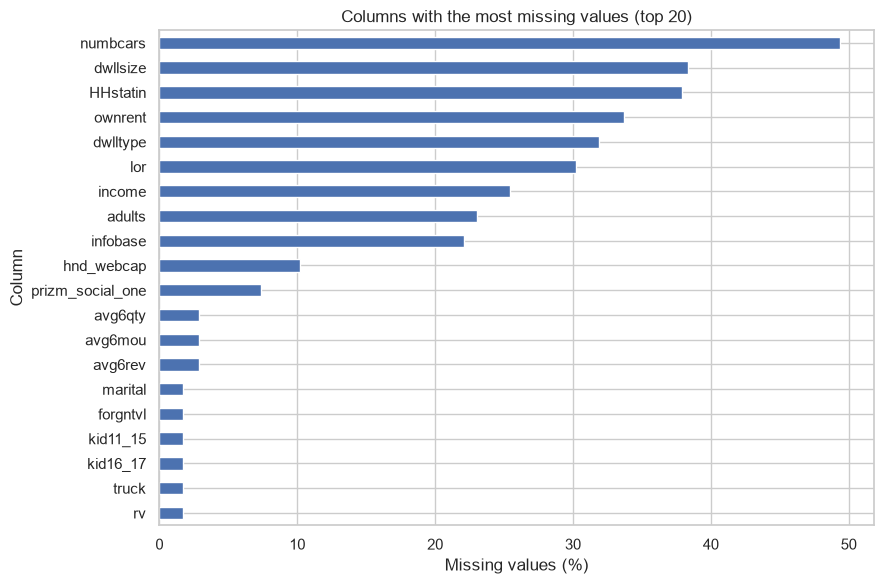

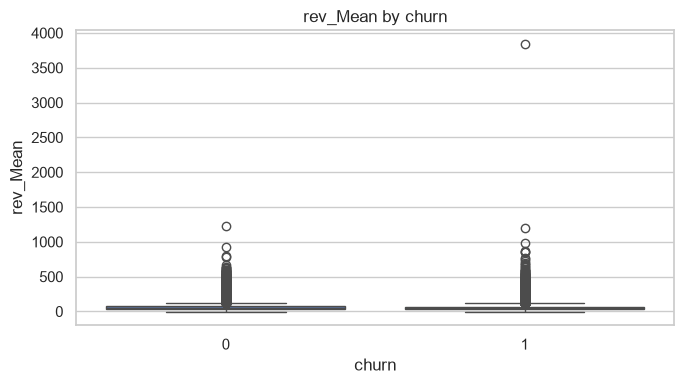

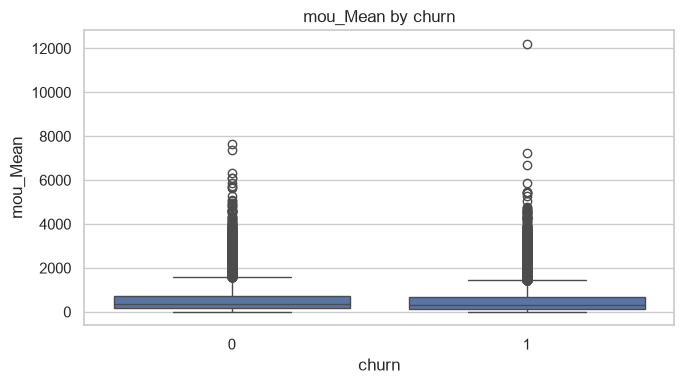

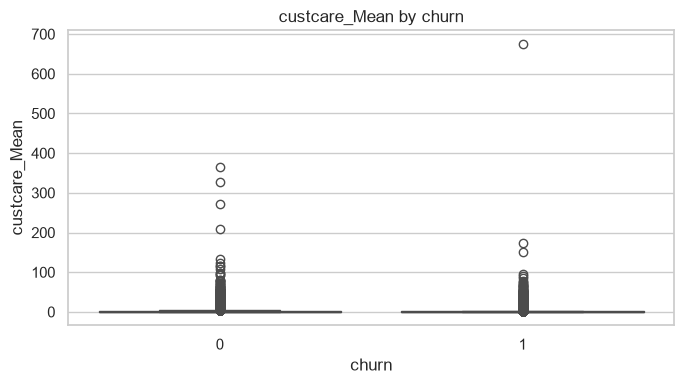

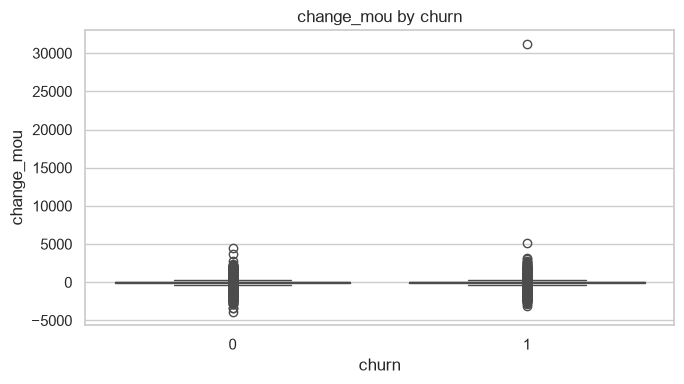

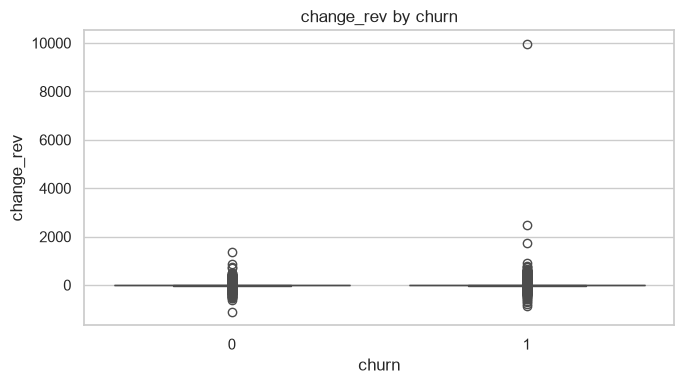

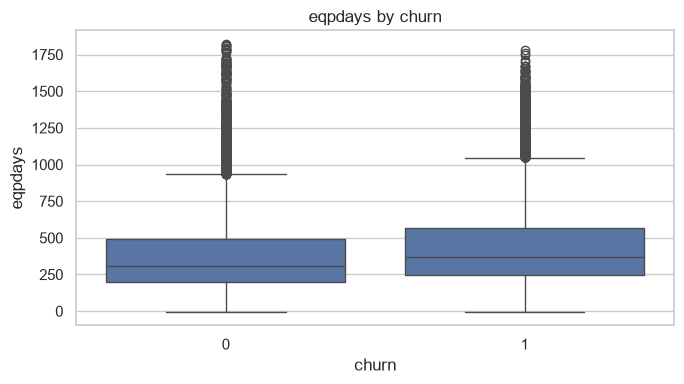

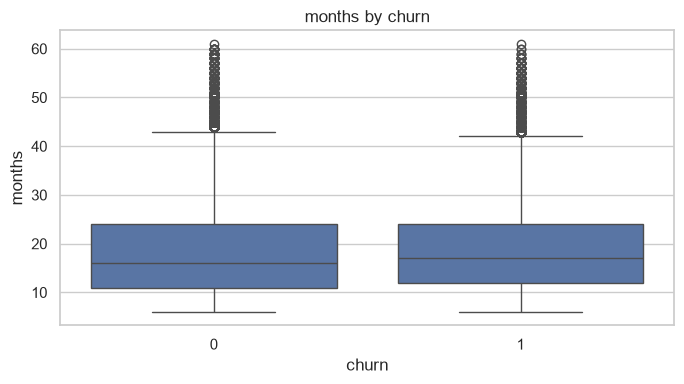

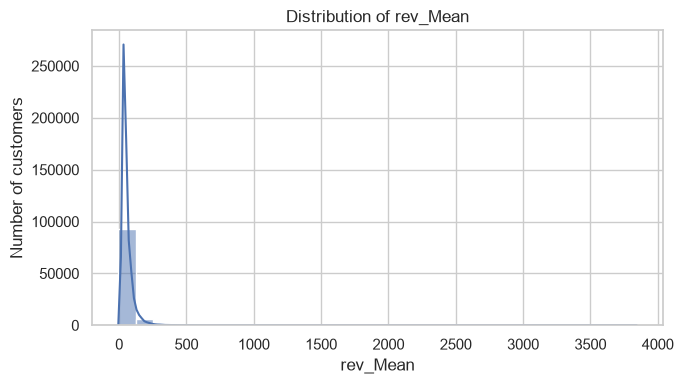

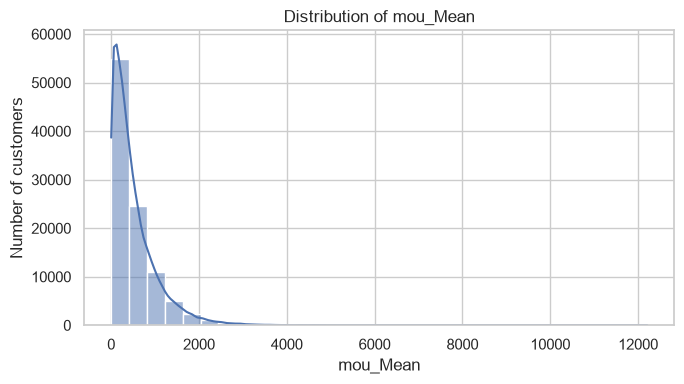

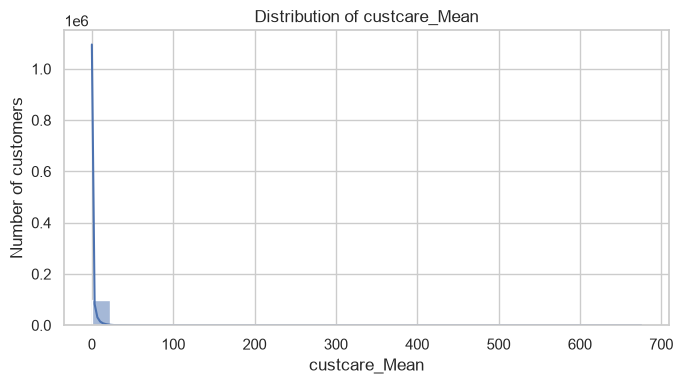

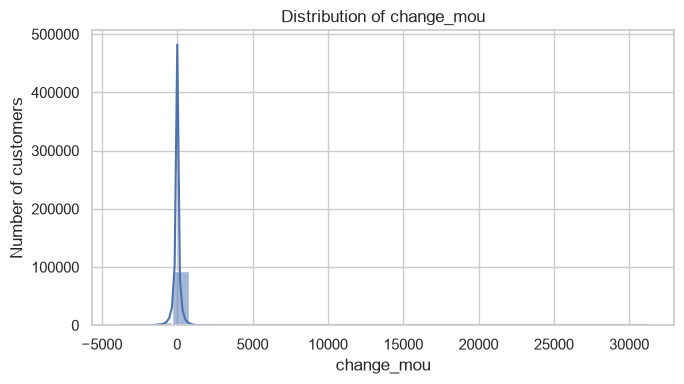

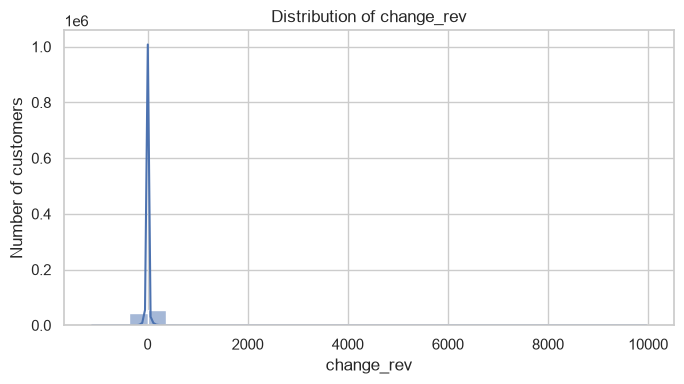

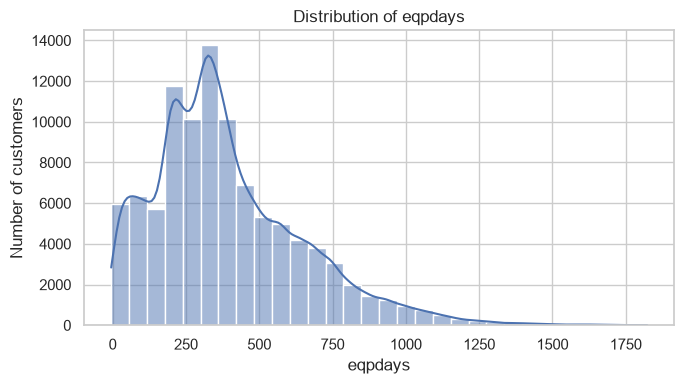

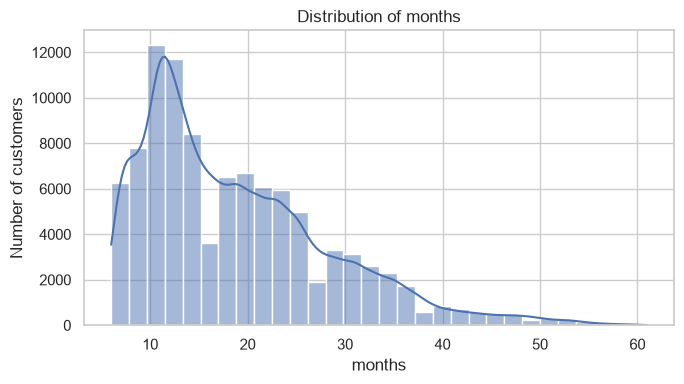

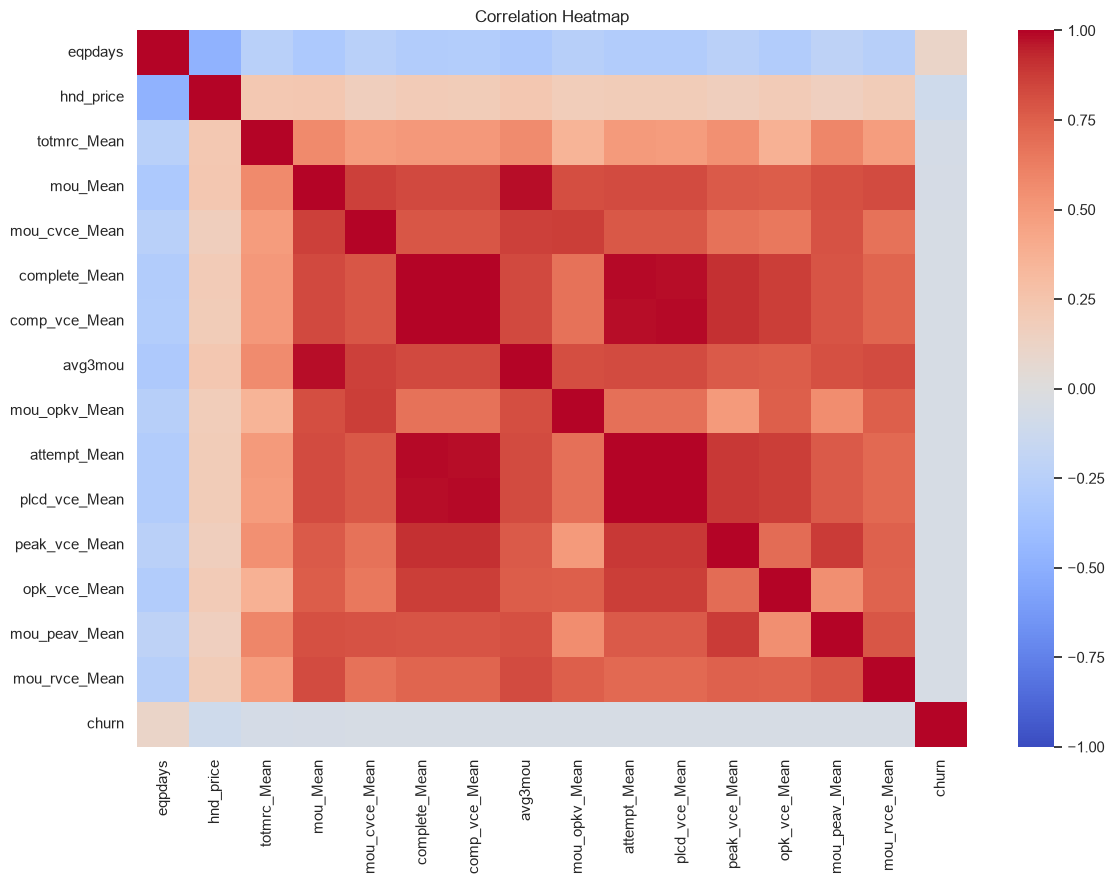

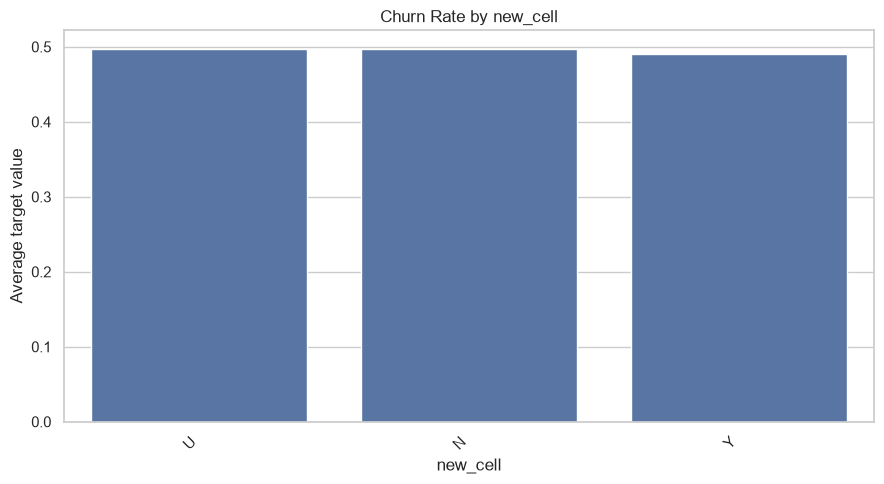

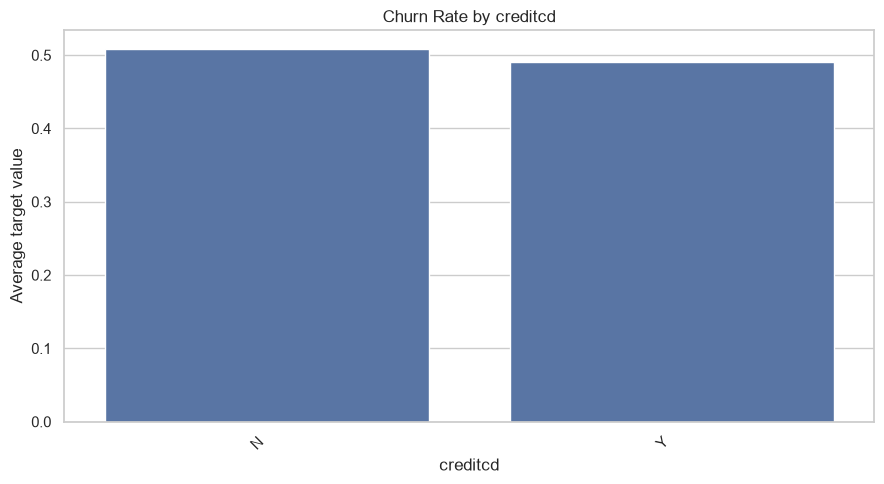

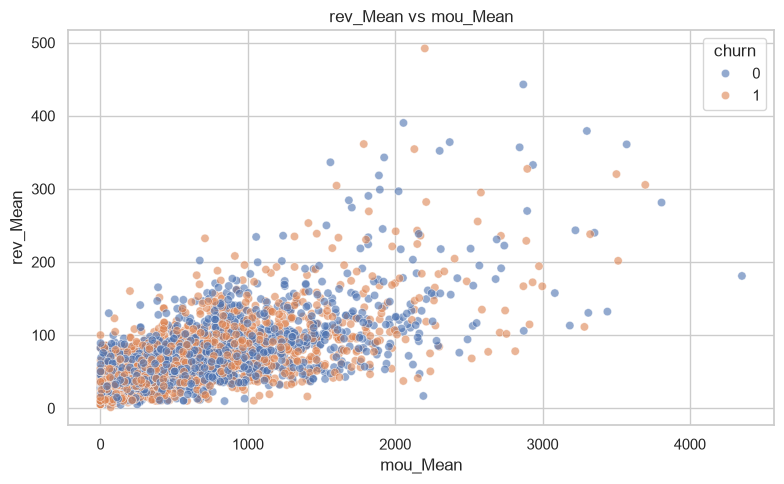

WindowsPath('C:/Users/princ/Company_A_Telecom_Project/outputs/figures/rev_Mean_vs_mou_Mean.png')

In [4]:
plot_target_distribution(df)
plot_missing_values(df)

eda_features = [
    "rev_Mean",
    "mou_Mean",
    "custcare_Mean",
    "change_mou",
    "change_rev",
    "eqpdays",
    "months"
]

plot_numeric_by_target(df, eda_features)

plot_distributions(df, eda_features)
plot_correlation_heatmap(df)

plot_churn_by_category(df, "new_cell")
plot_churn_by_category(df, "creditcd")

plot_scatter(df, "mou_Mean", "rev_Mean")

## 5. Train and compare baseline models

In [5]:
results = train_compare_models(df)
display(results["metrics"].round(4))
print("Constant columns removed:", results["constant_columns_removed"])

Training Logistic Regression...
Training Random Forest...


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC_Average_Precision
1,Random Forest,0.6241,0.6156,0.6435,0.6292,0.6760,0.6598
0,Logistic Regression,0.5961,0.5893,0.6102,0.5996,0.6295,0.6036


Constant columns removed: []


## 6. Evaluate the model selected by holdout ROC-AUC

Model selected for further inspection: Random Forest


,value
Model,Random Forest
Accuracy,0.624133
Precision,0.615583
Recall,0.643486
F1,0.629225
ROC_AUC,0.675978
PR_AUC_Average_Precision,0.659833


Selected model: Random Forest
              precision    recall  f1-score   support

     Class 0       0.63      0.61      0.62     15131
     Class 1       0.62      0.64      0.63     14869

    accuracy                           0.62     30000
   macro avg       0.62      0.62      0.62     30000
weighted avg       0.62      0.62      0.62     30000



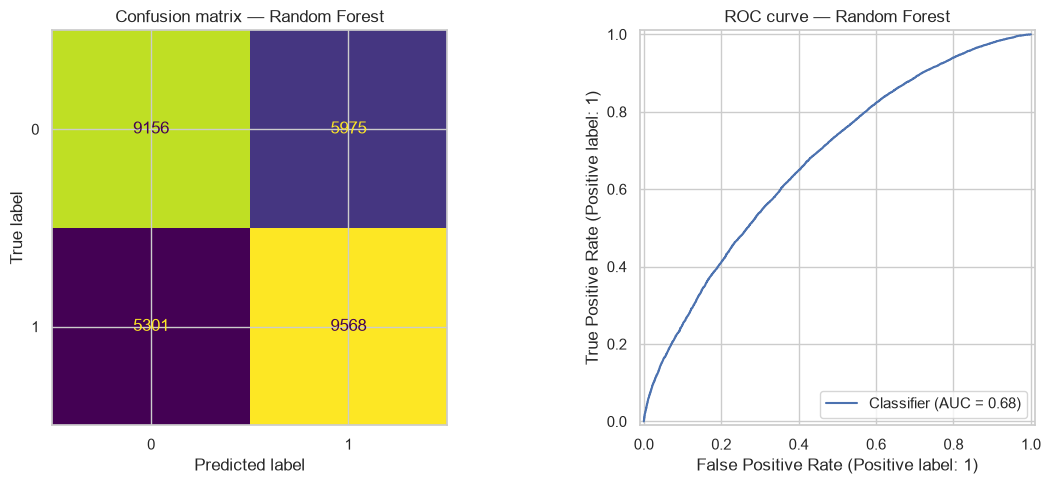

The Random Forest baseline achieved ROC-AUC 0.676, F1 0.629, precision 0.616, and recall 0.643 on a held-out test set. These scores describe predictive performance on this split; they do not prove that a retention intervention will cause customers to stay.


In [6]:
best_model_name = results["metrics"].iloc[0]["Model"]
best_metrics = results["metrics"].iloc[0]

print("Model selected for further inspection:", best_model_name)
display(best_metrics.to_frame("value"))
evaluate_selected_model(results, best_model_name)
print(metrics_summary(best_metrics))

## 7. Feature importance (when supported)

,Feature,Importance
76,numeric__eqpdays,0.041059
48,numeric__months,0.030327
9,numeric__change_mou,0.027805
1,numeric__mou_Mean,0.022051
54,numeric__adjrev,0.021577
53,numeric__totrev,0.020891
59,numeric__avgqty,0.020470
10,numeric__change_rev,0.020137
57,numeric__avgrev,0.020057
58,numeric__avgmou,0.019991


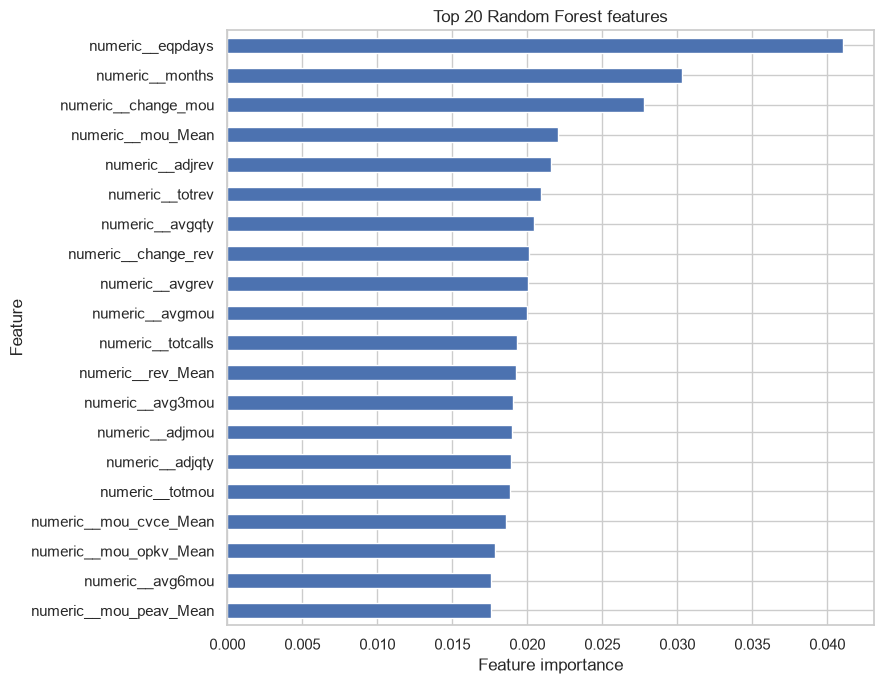

In [7]:
if best_model_name == "Random Forest":
    importance = feature_importance(results["models"][best_model_name], top_n=20)
    display(importance)
    ax = importance.sort_values("Importance").plot(
        x="Feature", y="Importance", kind="barh", figsize=(9, 7), legend=False
    )
    ax.set_title("Top 20 Random Forest features")
    ax.set_xlabel("Feature importance")
    plt.tight_layout()
    plt.show()
else:
    print("The selected model is Logistic Regression. Interpret coefficients separately if needed.")

## 8. Retrospective targeting analysis

In [8]:
risk_ranking = make_risk_ranking(results, best_model_name)
top_group_results = top_group_lift(risk_ranking, share=0.10)

display(pd.DataFrame([top_group_results]))
print(business_summary(top_group_results))

,test_rows,target_share,selected_rows,observed_positive_rate_top_group,observed_positive_rate_full_test,share_of_actual_positives_captured
0,30000,0.1,3000,0.760333,0.495633,0.153406


The highest-risk 10% of the test set contained 3,000 records. The observed positive rate in this group was 76.0%, compared with 49.6% in the full test set. This group captured 15.3% of positive cases in the test set. Treat this as retrospective targeting analysis, not evidence of causal campaign impact.


## 9. Optional business scenario calculator

The values below are **illustrative placeholders, not facts about Company A**. Replace them with credible values from external sources or clearly label the results as sensitivity scenarios. The retention rate must be incremental lift attributable to the intervention, not merely the model's predicted probability.

In [9]:
scenario = scenario_calculator(
    customer_count=len(df),
    target_share=0.10,
    intervention_cost=10.0,
    incremental_retention_rate=0.20,
    value_per_retained_customer=100.0,
)
display(pd.Series(scenario))

customer_count                                                               100000
targeted_customers                                                            10000
estimated_incremental_retained                                               2000.0
campaign_cost                                                              100000.0
estimated_benefit                                                          200000.0
estimated_net_benefit                                                      100000.0
assumptions                       {'target_share': 0.1, 'intervention_cost': 10....
dtype: object

## 10. Interpretation notes for your report

Write your own short interpretation after reviewing the outputs:

1. What patterns did EDA show?
2. Why is churn an appropriate target for this PoC?
3. Which model performed better, and on which metrics?
4. What are the top actionable signals, and what are the limitations?
5. How would Company A pilot the proposal and measure incremental impact?

Remember: predictive association is not causal evidence. Include external market research and references in the final slides, and include the required AI chat-history URL if you use this assistance.